In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cftime
import cfr
import scipy.stats 
import pandas as pd

In [ ]:
# LMR Reproduced
res_lmr = cfr.ReconRes('./recons/lmr_reproduce_pda_ptype_res/')
res_lmr.load(['tas', 'tas_gm'])
lmr_fd = res_lmr.recons['tas']
lmr_ts = res_lmr.recons['tas_gm']

# PReSto2k class-based
res_pc = cfr.ReconRes('./recons/presto2k/')
res_pc.load(['tas', 'tas_gm'])
pc_fd = res_pc.recons['tas']
pc_ts = res_pc.recons['tas_gm']

# DOCU-PReSto
res_dp = cfr.ReconRes('./recons/docu_presto/')
res_dp.load(['tas', 'tas_gm'])
dp_fd = res_dp.recons['tas']
dp_ts = res_dp.recons['tas_gm']

In [3]:
### ----------- LMR v PReSto2k ----------------

#  High KD year (different)
lmr_937 = lmr_fd['937']
pc_937 =  pc_fd['937']

lmr_1529 = lmr_fd['1529']
pc_1529 =  pc_fd['1529']



In [31]:
high_937 = pc_937-lmr_937
high_1529 = pc_1529-lmr_1529


(<Figure size 1000x800 with 2 Axes>,
 <GeoAxes: title={'center': 'PReSto2k-LMR Year 1529 (KD=0.98,|$\\Delta$ GMST|=0.162 )'}>)

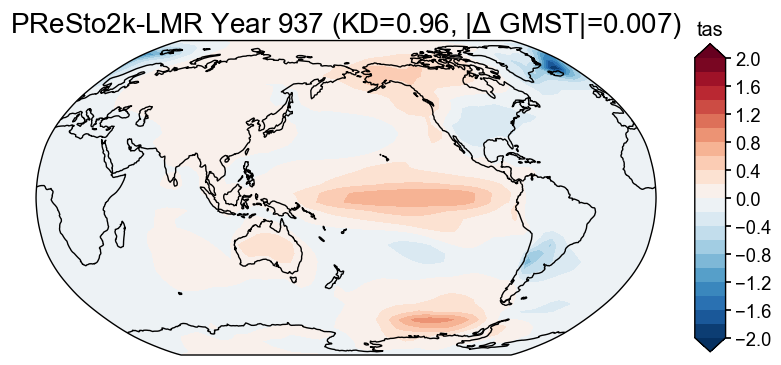

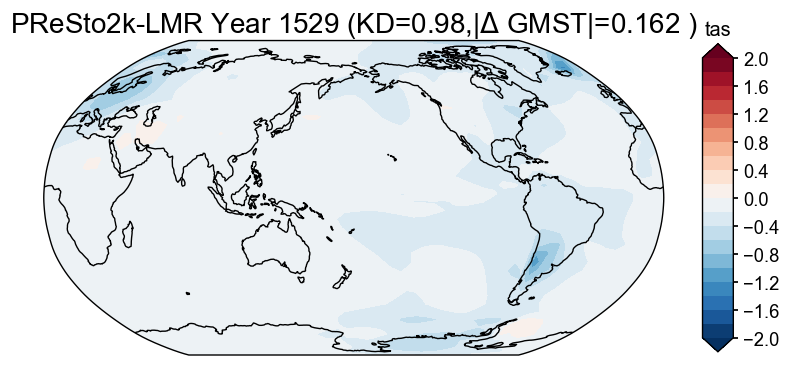

In [32]:
high_937.plot(title = r'PReSto2k-LMR Year 937 (KD=0.96, |$\Delta$ GMST|=0.007)',
            levels=np.linspace(-2, 2, 21),
            cbar_labels=np.linspace(-2, 2, 11),
            extend='both'
        )

high_1529.plot(title = r'PReSto2k-LMR Year 1529 (KD=0.98,|$\Delta$ GMST|=0.162 )',
            levels=np.linspace(-2, 2, 21),
            cbar_labels=np.linspace(-2, 2, 11),
            extend='both'
        )

In [33]:
### ----------- LMR v DOCU-PReSto ----------------

#  High KD year (different)
lmr_1448 = lmr_fd['1448']
dp_1448 =  dp_fd['1448']

lmr_1735 = lmr_fd['1735']
dp_1735 =  dp_fd['1735']


In [34]:
high_1448 = dp_1448-lmr_1448
high_1735 = dp_1735-lmr_1735


(<Figure size 1000x800 with 2 Axes>,
 <GeoAxes: title={'center': 'DOCU-LMR Year 1735 (KD=0.96, |$\\Delta$ GMST|=0.0012)'}>)

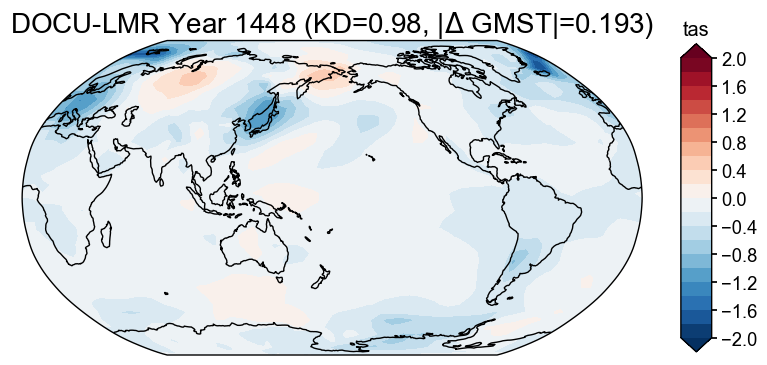

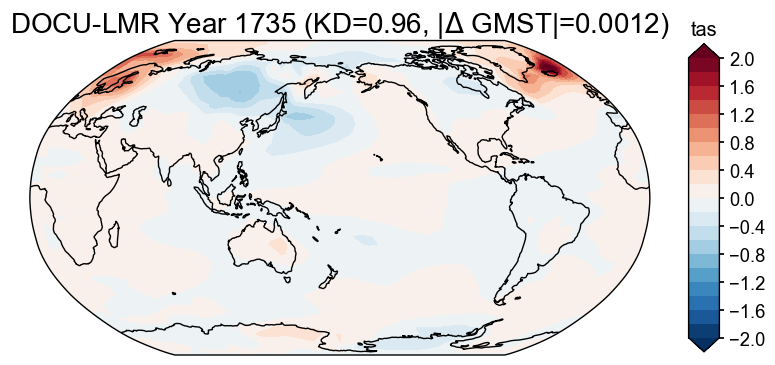

In [37]:
high_1448.plot(title = r'DOCU-LMR Year 1448 (KD=0.98, |$\Delta$ GMST|=0.193)',
            levels=np.linspace(-2, 2, 21),
            cbar_labels=np.linspace(-2, 2, 11),
            extend='both'
        )

high_1735.plot(title = r'DOCU-LMR Year 1735 (KD=0.96, |$\Delta$ GMST|=0.0012)',
            levels=np.linspace(-2, 2, 21),
            cbar_labels=np.linspace(-2, 2, 11),
            extend='both'
        )

## Load PDB

In [ ]:
lmr_presto_diff = cfr.ProxyDatabase().load_nc('./prev_data/pdb/lmr_presto_totaldiff_pdb.nc')
lmr_presto_diff.refresh()

lmr_docu_diff = cfr.ProxyDatabase().load_nc('./prev_data/pdb/lmr_docu_totaldiff_pdb.nc')
lmr_docu_diff.refresh()


lmr_og = cfr.ProxyDatabase().load_nc('./prev_data/pdb/lmr_repro_pdb_calib.nc')
pc_og = cfr.ProxyDatabase().load_nc('./prev_data/pdb/presto_pdb_calib.nc')
dp_og = cfr.ProxyDatabase().load_nc('./prev_data/pdb/docu_presto_tas_pdb_calib.nc')

In [5]:
from cfr.visual import STYLE
import seaborn as sns


STYLE.colors_dict.update({
    'temperature_index': sns.xkcd_rgb['purple'],
    'plant_phenology': sns.xkcd_rgb['red'],
    'other.Temperautre_reconstruction': sns.xkcd_rgb['green'],
    'ice_phenology': sns.xkcd_rgb['light blue']
})

STYLE.markers_dict.update({
    'temperature_index': 'o',
    'plant_phenology': 'o',
    'other.Temperautre_reconstruction': 'o',
    'ice_phenology': 'o'
})

(<Figure size 1200x400 with 2 Axes>,
 {'ts': <Axes: title={'center': '101 (other.Temperautre_reconstruction) @ (lat:29.00, lon:117.50)'}, xlabel='Time [yr]', ylabel='Proxy Value [none]'>,
  'map': <GeoAxes: >})

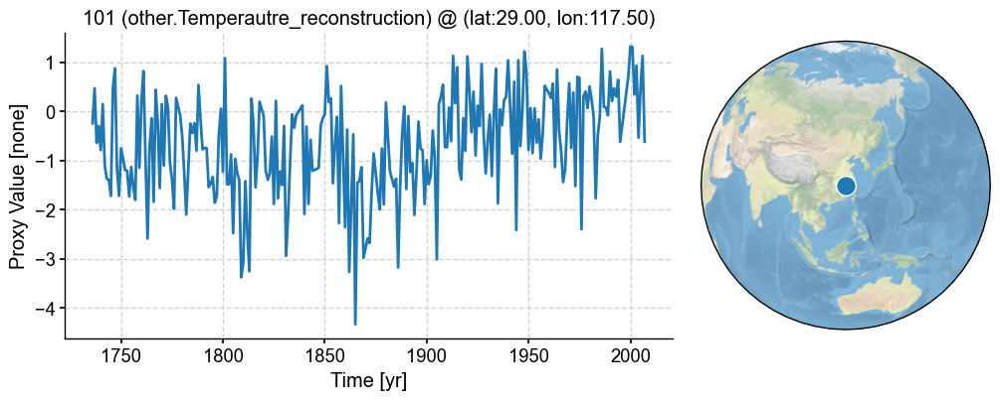

In [13]:
lmr_docu_diff['101'].plot()

(<Figure size 1000x1000 with 2 Axes>,
 {'map': <GeoAxes: title={'center': 'LMRv2.1* Calibrated PDB'}>,
  'count': <Axes: xlabel='Year (AD)', ylabel='number of proxies'>})

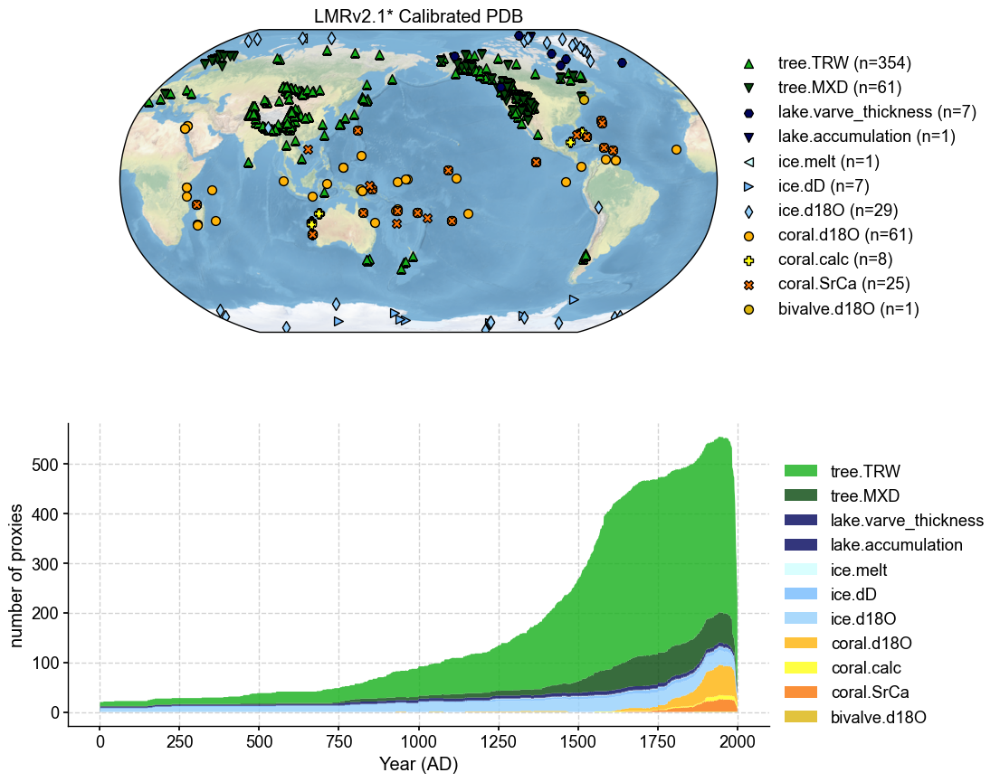

In [305]:
lmr_og.plot(title='LMRv2.1* Calibrated PDB', plot_count=True)

(<Figure size 1000x1000 with 2 Axes>,
 {'map': <GeoAxes: title={'center': 'PReSto2k-DOCU Calibrated PDB'}>,
  'count': <Axes: xlabel='Year (AD)', ylabel='number of proxies'>})

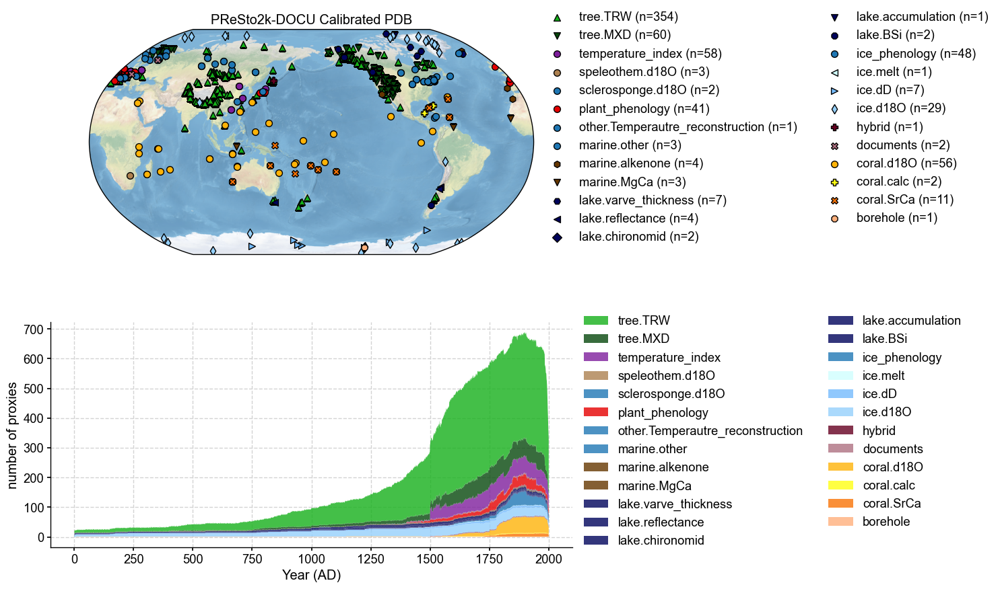

In [304]:
dp_og.plot(title='PReSto2k-DOCU Calibrated PDB', plot_count=True)

In [9]:
def get_pdb_year(pdb, year):
    """
    Filter a ProxyDatabase to only include records with data in a specific year.
    
    Parameters:
    -----------
    pdb : cfr.ProxyDatabase
        The proxy database object
    year : int
        The year to filter for
    
    Returns:
    --------
    cfr.ProxyDatabase : New ProxyDatabase with only records containing the specified year
    """
    from cfr.proxy import ProxyDatabase
    
    filtered_pdb = ProxyDatabase()
    
    for pid, pobj in pdb.records.items():
        # Check if this proxy has data for the specified year
        if year in pobj.time:
            filtered_pdb += pobj
    
    filtered_pdb.refresh()
    return filtered_pdb


In [10]:
lmrz_fd = lmr_fd['1816']
other_fd =  dp_fd['1816']


diff_fd = other_fd - lmrz_fd

In [11]:
diff_fd.da.values.mean()

0.023651257233508607

In [12]:
lohi = get_pdb_year(lmr_og, 1816)
lohi2 = get_pdb_year(dp_og,1816)



In [13]:
from pdb_utils import *

In [14]:
# Now test the  matching
matches, conflicts, missing = match_proxy_records(lohi, lohi2)

print("=== MATCHING RESULTS ===")
print(f"Matches found: {len(matches)}")
print(f"Conflicts: {len(conflicts)}")
print(f"Missing from PReSto2k: {len(missing)}")

=== MATCHING RESULTS ===
Matches found: 488
Conflicts: 0
Missing from PReSto2k: 1


In [15]:
renamed1448 = rename_pids(lohi2, matches, in_place=False)

In [16]:
diff1448 = renamed1448 - lohi
diff21448 = lohi-renamed1448

>>> Subtracting NAm_131 failed.
>>> Subtracting SAm-LagunaChepical.deJong.2013_SAm_025 failed.
>>> Subtracting Ocn-NorthIceland.Sicre.2011_O2kLR_045 failed.
>>> Subtracting Ant-WAIS-Divide.Severinghaus.2012_LPDb9285123 failed.
>>> Subtracting Eur-Tallinn.Tarand.2001_Eur_026 failed.
>>> Subtracting SAm-LagunaAculeo.vonGunten.2009_SAm_0243 failed.
>>> Subtracting Eur-CentralEurope.Dobrovolny.2009_Eur_022 failed.
>>> Subtracting SAm-LagunaEscondida.Elbert.2013_SAm_032 failed.
>>> Subtracting Eur-LakeSilvaplana.Trachsel.2010_Eur_002 failed.
>>> Subtracting Aus-DuckholeLake.Saunders.2013_LPD335d863f failed.
>>> Subtracting Eur-NorthernSpain.Martin-Chivelet.2011_Eur_008 failed.
>>> Subtracting Eur-LakeSilvaplana.Larocque-Tobler.2010_Eur_003 failed.
>>> Subtracting Ocn-EasternTropicalNorthAtlantic.Kuhnert.2011_LPD13a78f9b failed.
>>> Subtracting Ocn-CariacoBasin.Black.2007_LPDe51d17e8 failed.
>>> Subtracting Asi-KunashirIsland.Demezhko.2009_Asia_235 failed.
>>> Subtracting Arc-StoreggaSlide.S

In [17]:
total_diff_1448 = diff1448+diff21448

Text(0.5, 1.0, '$\\Delta T$')

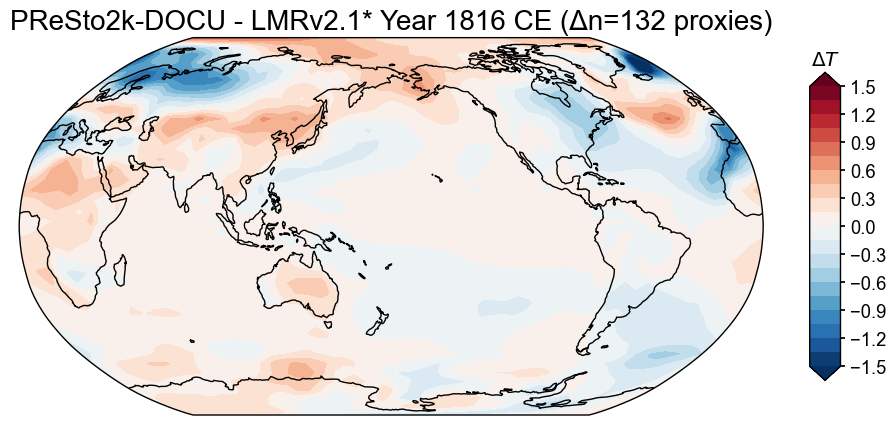

In [18]:
year = 1816
name= 'PReSto2k-DOCU - LMRv2.1*'
pdb = total_diff_1448

fig, ax = diff_fd.plot(
    title=f'{name} Year {year} CE (Δn={pdb.nrec} proxies)',
    plot_proxydb=False,
    proxydb=pdb,
    plot_proxydb_lgd=True,
    proxydb_lgd_kws={
        'bbox_to_anchor': (1.2, 1),  # Position outside the plot on the right
        'loc': 'upper left',
        'frameon': False,
        'ncol': 1
    },
    site_markersize=80,
    levels=np.linspace(-1.5, 1.5, 21),
    cbar_labels=np.linspace(-1.5, 1.5, 11),
    extend='both',
    figsize=[12, 8]
)
cbar_ax = fig.axes[-1]  # Get colorbar axis
cbar_ax.set_title(r'$\Delta T$', pad=15)

## 1816

In [20]:
pdb_og = get_pdb_year(lmr_og, 1816)
og_fd = lmr_fd['1816']

Text(0.5, 1.0, '$T$')

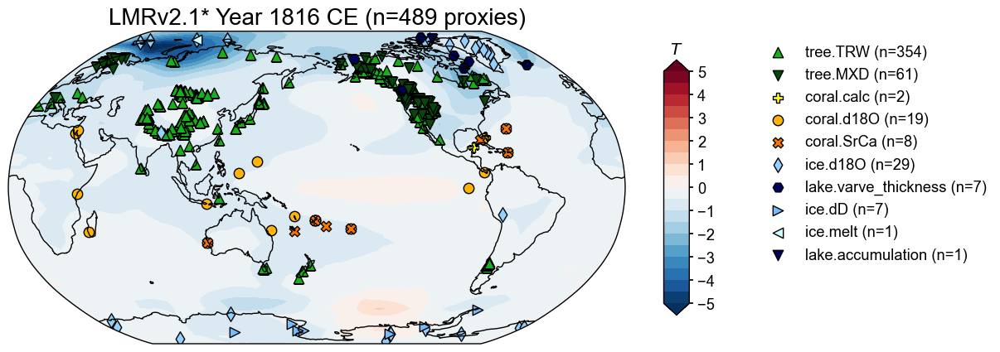

In [22]:
year = 1816
name= 'LMRv2.1*'

fig, ax = og_fd.plot(
    title=f'{name} Year {year} CE (n={pdb_og.nrec} proxies)',
    plot_proxydb=True,
    proxydb=pdb_og,
    plot_proxydb_lgd=True,
    proxydb_lgd_kws={
        'bbox_to_anchor': (1.2, 1),  # Position outside the plot on the right
        'loc': 'upper left',
        'frameon': False,
        'ncol': 1
    },
    site_markersize=80,
    levels=np.linspace(-5, 5, 21),
    cbar_labels=np.linspace(-5, 5, 11),
    extend='both',
    figsize=[12, 8]
)
cbar_ax = fig.axes[-1]  # Get colorbar axis
cbar_ax.set_title(r'$T$', pad=15)

In [227]:
pdb_og = get_pdb_year(pc_og, 1816)
og_fd = pc_fd['1816']

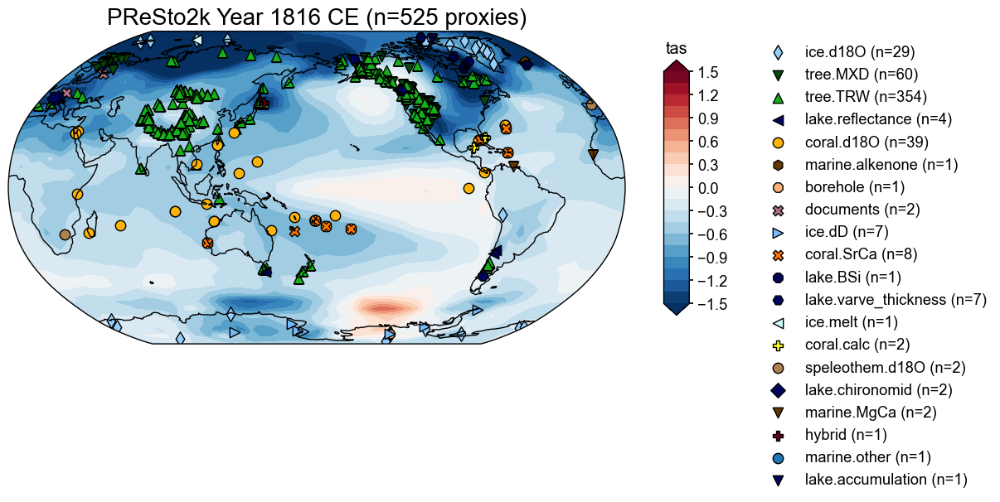

In [ ]:
year = 1816
name= 'PReSto2k'

fig, ax = og_fd.plot(
    title=f'{name} Year {year} CE (n={pdb_og.nrec} proxies)',
    plot_proxydb=True,
    proxydb=pdb_og,
    plot_proxydb_lgd=True,
    proxydb_lgd_kws={
        'bbox_to_anchor': (1.2, 1),  # Position outside the plot on the right
        'loc': 'upper left',
        'frameon': False,
        'ncol': 1
    },
    site_markersize=80,
    levels=np.linspace(-1.5, 1.5, 21),
    cbar_labels=np.linspace(-1.5, 1.5, 11),
    extend='both',
    figsize=[12, 8]
)

In [229]:
pdb_og = get_pdb_year(dp_og, 1816)
og_fd = dp_fd['1816']

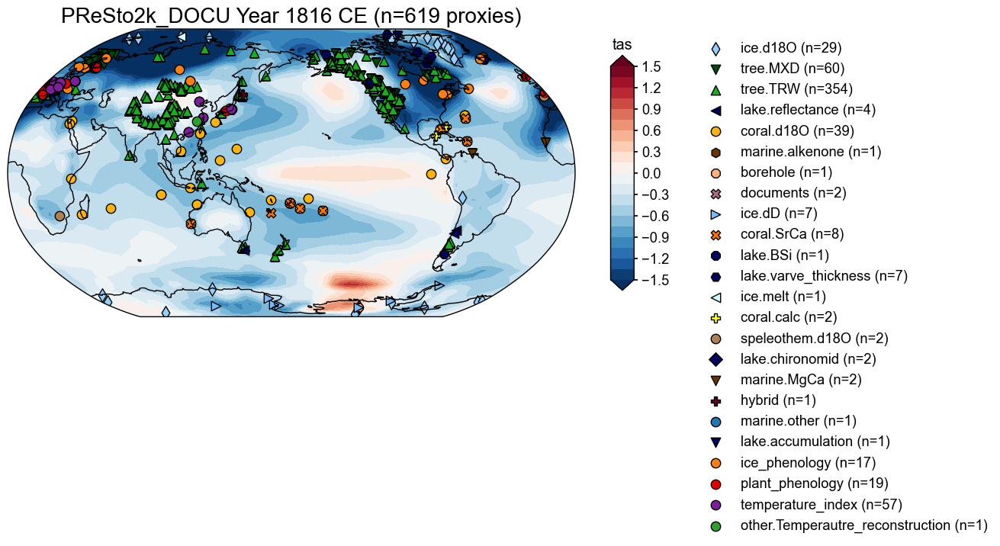

In [230]:
year = 1816
name= 'PReSto2k_DOCU'

fig, ax = og_fd.plot(
    title=f'{name} Year {year} CE (n={pdb_og.nrec} proxies)',
    plot_proxydb=True,
    proxydb=pdb_og,
    plot_proxydb_lgd=True,
    proxydb_lgd_kws={
        'bbox_to_anchor': (1.2, 1),  # Position outside the plot on the right
        'loc': 'upper left',
        'frameon': False,
        'ncol': 1
    },
    site_markersize=80,
    levels=np.linspace(-1.5, 1.5, 21),
    cbar_labels=np.linspace(-1.5, 1.5, 11),
    extend='both',
    figsize=[12, 8]
)

In [23]:
lmre = get_pdb_year(lmr_og, 934)
dpre = get_pdb_year(dp_og, 934)

diffe = dpre-lmre

>>> Subtracting Arc_071 failed.
>>> Subtracting Asi_098 failed.
>>> Subtracting Asi_155 failed.
>>> Subtracting Arc_001 failed.
>>> Subtracting Asi_052 failed.
>>> Subtracting Asi_084 failed.
>>> Subtracting NAm_050 failed.
>>> Subtracting Asi_202 failed.
>>> Subtracting Arc_035 failed.
>>> Subtracting NAm_049 failed.
>>> Subtracting Ocn_103 failed.
>>> Subtracting Arc_079 failed.
>>> Subtracting Asi_087 failed.
>>> Subtracting Ant_006 failed.
>>> Subtracting Aus_002 failed.
>>> Subtracting NAm_019 failed.
>>> Subtracting Ant_002 failed.
>>> Subtracting NAm_009 failed.
>>> Subtracting Arc_034 failed.
>>> Subtracting Eur_013 failed.
>>> Subtracting Arc_036 failed.
>>> Subtracting Asi_204 failed.
>>> Subtracting Arc_061 failed.
>>> Subtracting NAm_013 failed.
>>> Subtracting NAm_011 failed.
>>> Subtracting Asi_183 failed.
>>> Subtracting Asi_175 failed.
>>> Subtracting Asi_088 failed.
>>> Subtracting Asi_086 failed.
>>> Subtracting Asi_096 failed.
>>> Subtracting NAm_180 failed.
>>> Subt

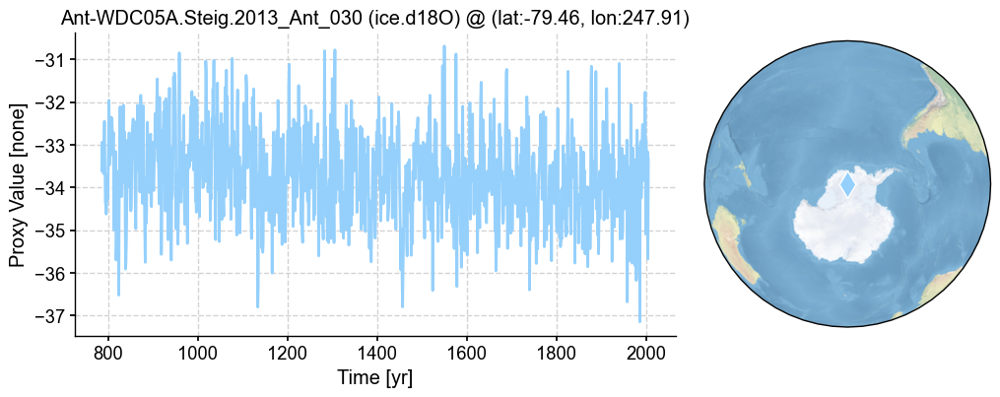

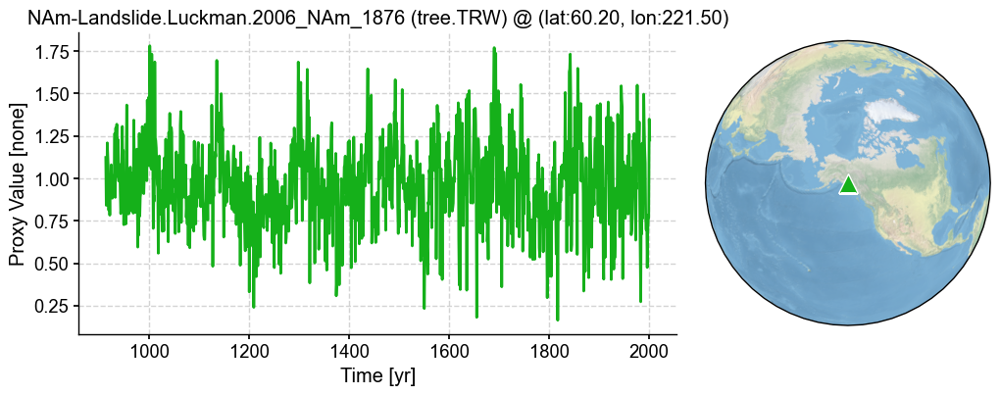

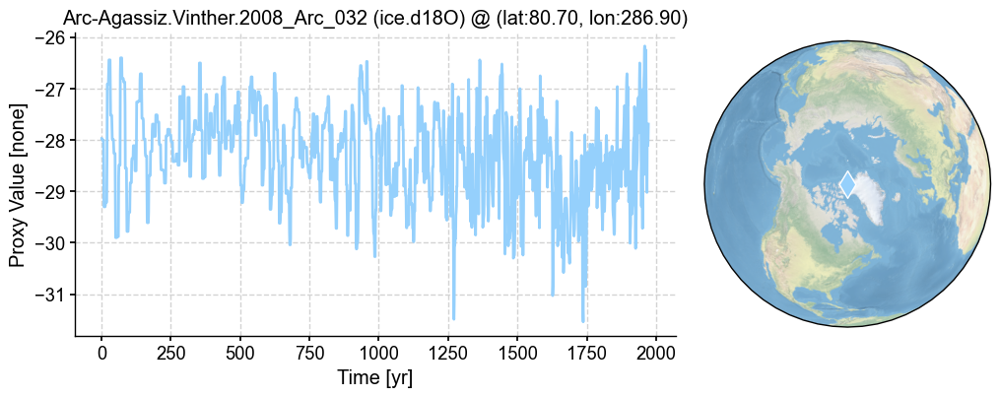

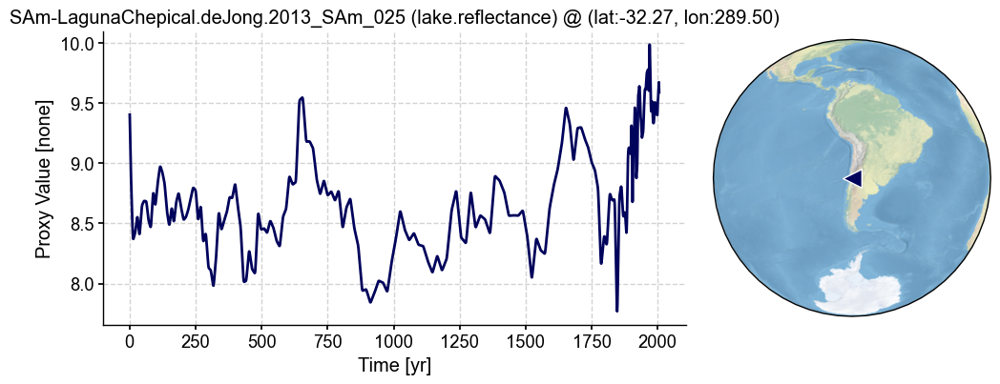

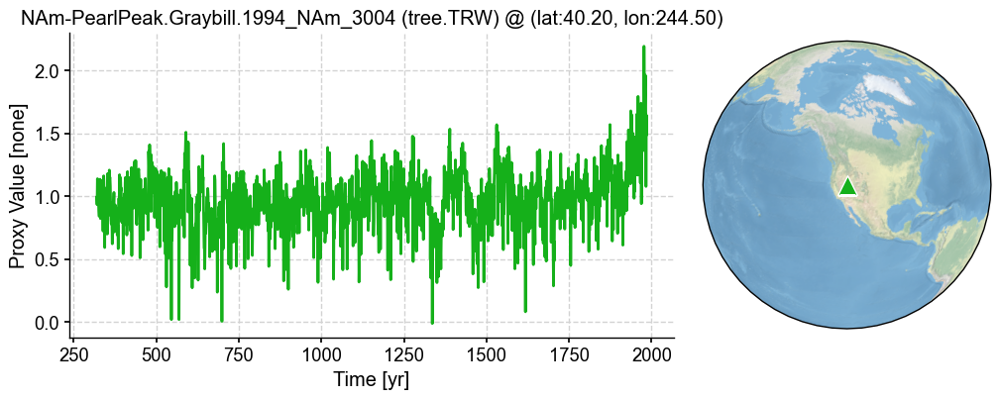

...

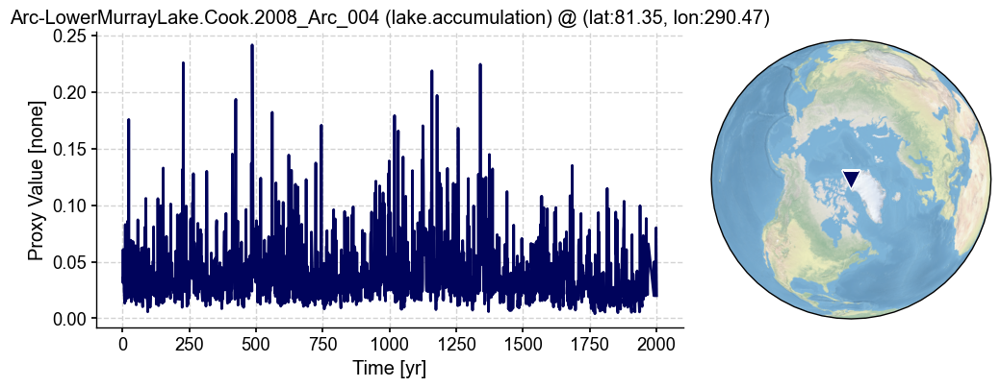

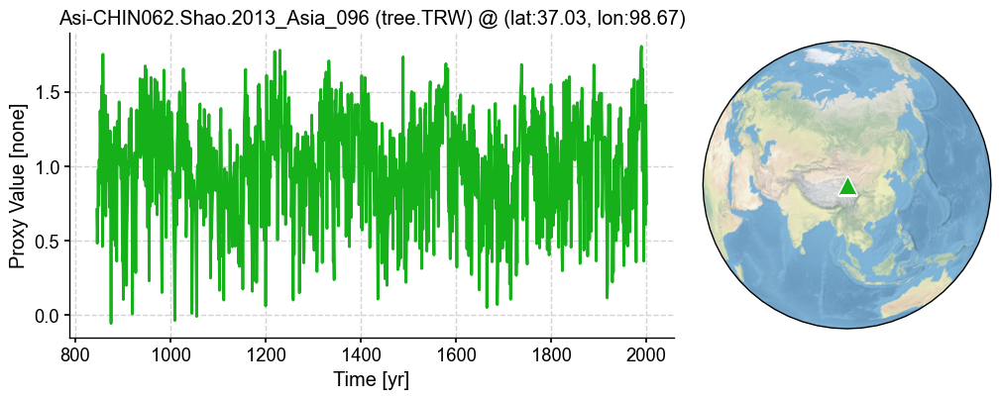

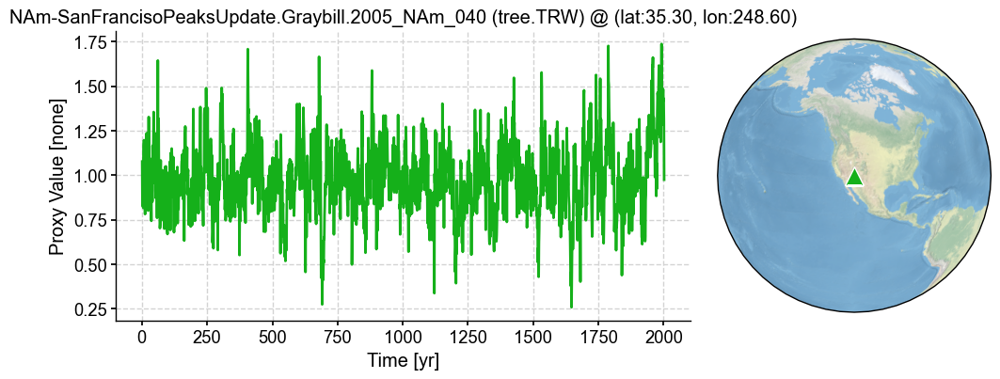

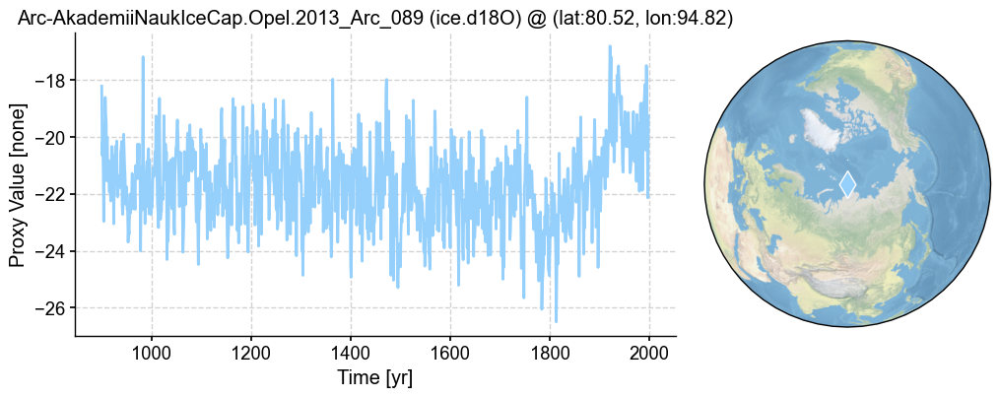

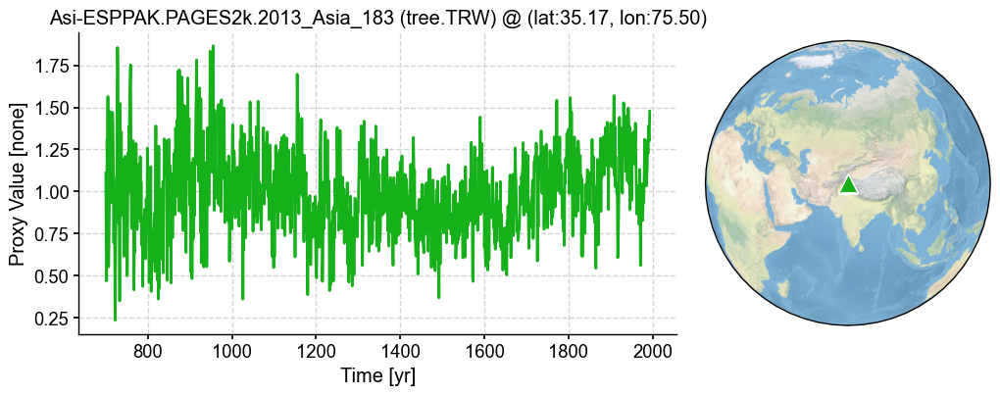

In [25]:
for rec in diffe.records:
    diffe[rec].plot()